In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import statsmodels.formula.api as smf
from scipy import stats
from linearmodels.panel import PanelOLS, RandomEffects

print("Import complete")

Import complete


---
## Part 2 : Difference-in-Differences（差分の差分法）

**分析の目的**  
山形県（・長崎県）が 2020 年から導入した **待機児童ゼロ化** の効果を DiD で推定する。

| 変数 | 内容 |
|------|------|
| `treated` | 処置群ダミー（処置群=1、対照群=0） |
| `post` | 政策後ダミー（2020年以降=1） |
| `treated:post` | 交差項 ＝ DiD 推定量（回帰式で直接生成） |
| `tfr` | 合計特殊出生率（目的変数） |

In [2]:
# ============================================================
# 定数
# ============================================================
YEARS_WAITLIST = list(range(2016, 2025))   # 待機児童数データの収録期間（2016〜2024年）

# ============================================================
# 1. 生データ読み込み
# ============================================================
df_tfr_raw = pd.read_csv(
    "../data/都道府県別_合計特殊出生率.csv",
    encoding="cp932",
    skiprows=9,          # 先頭9行はメタデータ
    na_values=["…"],
)

df_waitlist_raw = pd.read_excel(
    "../data/都道府県別_待機児童数.xlsx",
    sheet_name="待機児童数",
    header=0,   # 1行目がそのままカラム名（都道府県番号, 都道府県名, 2016, 2017, ...）
)

In [3]:
# ============================================================
# 2. 前処理
# ============================================================

# 合計特殊出生率
# 第1列を 'prefecture' にリネーム
df_tfr_clean = df_tfr_raw.rename(columns={df_tfr_raw.columns[0]: "prefecture"})

# 「全　国」行を除外
df_tfr_clean = df_tfr_clean[df_tfr_clean["prefecture"] != "全　国"].copy()

# 都道府県コード（数字2桁）を抽出して 'pref_code' 列を作成（"01 北海道" → 1）
df_tfr_clean["pref_code"] = df_tfr_clean["prefecture"].str.extract(r"^(\d{2})").astype(int)

# wide → long 変換（tidy形式）
year_cols = [c for c in df_tfr_clean.columns if str(c).isdigit()]
df_tfr = df_tfr_clean.melt(
    id_vars=["pref_code", "prefecture"],   # 列として固定したままにするもの
    value_vars=year_cols,   # 縦に展開する列
    var_name="year",   # 縦に展開した列の名前
    value_name="tfr",   # 縦に展開した列の値の列名
)

# 年を int 型に変換
df_tfr["year"] = df_tfr["year"].astype(int)

In [4]:
# 待機児童数
# '都道府県番号'→'pref_code'、'都道府県名'→'prefecture' にリネーム
df_waitlist_clean = df_waitlist_raw.rename(columns={"都道府県番号": "pref_code", "都道府県名": "prefecture"})

# 「都道府県計」（全国合計）行を除外（prefectureがNaNの行として判別）
df_waitlist_clean = df_waitlist_clean[df_waitlist_clean["prefecture"].notna()].copy()

# pref_codeを int 型に変換
df_waitlist_clean["pref_code"] = df_waitlist_clean["pref_code"].astype(int)

# wide → long 変換（tidy形式）
year_cols = [c for c in df_waitlist_clean.columns if str(c).isdigit()]
df_waitlist = df_waitlist_clean.melt(
    id_vars=["pref_code", "prefecture"],
    value_vars=year_cols,
    var_name="year",
    value_name="waitlist",
)

# 年を int 型に変換
df_waitlist["year"] = df_waitlist["year"].astype(int)

In [5]:
# ============================================================
# 3. 分析用データセット：出生率データとマージ（2016〜2024年に絞る）
# ============================================================
# df_tfr は2009年以降を含むため2016〜2024年に絞り込む
# df_waitlist はもともと2016〜2024年のみのため絞り込み不要
df_tfr_main = df_tfr[df_tfr["year"].isin(YEARS_WAITLIST)]

df_panel = pd.merge(
    df_tfr_main,
    df_waitlist[["pref_code", "year", "waitlist"]],
    on=["pref_code", "year"],
    how="inner",
)

df_panel = df_panel.sort_values(["pref_code", "year"]).reset_index(drop=True)

In [6]:
# ============================================================
# 4. 確認出力
# ============================================================
print("=== df_panel（先頭5行）===")
print(df_panel.head())
print()
print(f"行数: {len(df_panel)}  （期待値: 47都道府県 × {len(YEARS_WAITLIST)}年 = {47 * len(YEARS_WAITLIST)}）")
print()
print("=== 欠損値確認 ===")
print(df_panel.isnull().sum())
print()
print("=== 基本統計量 ===")
print(df_panel[["tfr", "waitlist"]].describe().round(3))

=== df_panel（先頭5行）===
   pref_code prefecture  year   tfr  waitlist
0          1     01 北海道  2016  1.29        94
1          1     01 北海道  2017  1.29        65
2          1     01 北海道  2018  1.27       129
3          1     01 北海道  2019  1.24       152
4          1     01 北海道  2020  1.21       134

行数: 423  （期待値: 47都道府県 × 9年 = 423）

=== 欠損値確認 ===
pref_code     0
prefecture    0
year          0
tfr           0
waitlist      0
dtype: int64

=== 基本統計量 ===
           tfr  waitlist
count  423.000   423.000
mean     1.411   266.111
std      0.167   755.403
min      0.960     0.000
25%      1.300     2.500
50%      1.420    46.000
75%      1.530   216.000
max      1.950  8586.000


処置群の候補（ある時点までは待機児童数が一定数いて、その後ゼロになる）：
- 2020年以降の山形県（2020年以降、待機児童数ゼロ）
- 2020年以降の長崎県（2020年以降、待機児童数ゼロ）
- 2021年以降の大分県（2021年以降、待機児童数ゼロ）

対照群の候補（全期間で一貫して待機児童数が多い）：
- 三重県
- 和歌山県

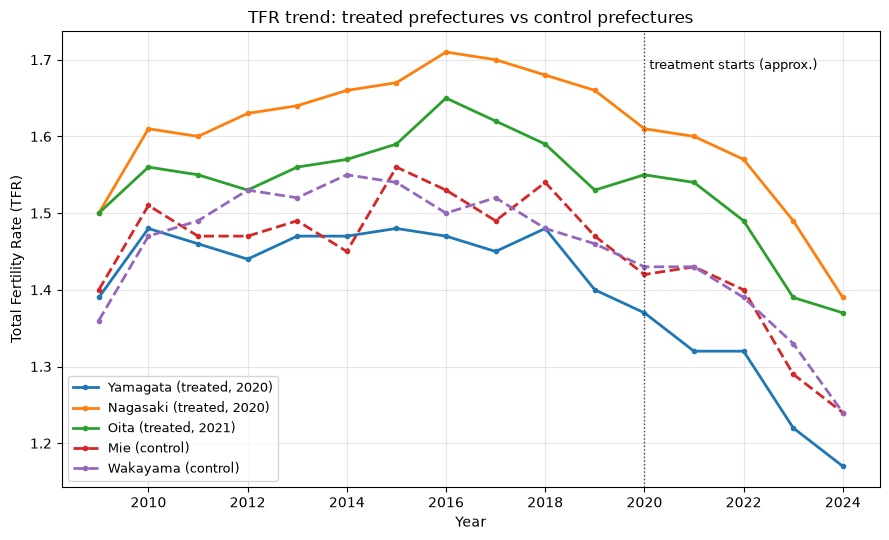

In [7]:
# ============================================================
# 可視化：処置群 vs 対照群のTFR推移（処置前トレンドの確認）
# ============================================================
# 注意：グラフ内の文字化けを防ぐため、凡例・軸ラベル・タイトルはすべて英語表記にする
#       （日本語フォントがない環境で実行すると文字が □□□ になるバグを避けるため）

# df_panel（df_tfr等）から都道府県ごとのTFR推移をピボットして取り出す想定
# 処置群：山形県・長崎県・大分県、対照群：三重県・和歌山県
target_prefs = {
    "06 山形県": "Yamagata (treated, 2020)",
    "42 長崎県": "Nagasaki (treated, 2020)",
    "44 大分県": "Oita (treated, 2021)",
    "24 三重県": "Mie (control)",
    "30 和歌山県": "Wakayama (control)",
}

# 処置群かどうかで線種を分けるための判定用リスト
treated_prefs = ["06 山形県", "42 長崎県", "44 大分県"]

# プロット対象を抽出（2009〜2024年）
df_plot = df_tfr[df_tfr["prefecture"].isin(target_prefs.keys())]
df_plot = df_plot[df_plot["year"].between(2009, 2024)]

# year × prefecture のピボットテーブルに変換（プロットしやすくするため）
pivot = df_plot.pivot(index="year", columns="prefecture", values="tfr")

# ============================================================
# グラフ描画
# ============================================================
fig, ax = plt.subplots(figsize=(9, 5.5))

for pref_code, label in target_prefs.items():
    # 処置群は実線、対照群は破線にして視覚的に区別する
    linestyle = "-" if pref_code in treated_prefs else "--"
    ax.plot(
        pivot.index,
        pivot[pref_code],
        label=label,
        linestyle=linestyle,
        linewidth=2,
        marker="o",
        markersize=3,
    )

# 処置年の目安として2020年の位置に縦の補助線を入れる
# （山形・長崎は2020年処置、大分は2021年処置なので、境目の目安として表示）
ax.axvline(x=2020, color="black", linestyle=":", linewidth=1, alpha=0.7)
ax.text(2020.1, ax.get_ylim()[1] * 0.98, "treatment starts (approx.)",
        fontsize=9, color="black", va="top")

# 軸ラベル・タイトル（すべて英語表記でバグ防止）
ax.set_xlabel("Year")
ax.set_ylabel("Total Fertility Rate (TFR)")
ax.set_title("TFR trend: treated prefectures vs control prefectures")

# 凡例は英語ラベルのみを使用
ax.legend(loc="lower left", fontsize=9)

# 見やすさのため薄いグリッド線を追加
ax.grid(True, alpha=0.3)

fig.tight_layout()

fig.savefig("../images/tfr_pretrend_check.png", dpi=150)
plt.show()

処置前期間（2009〜2019年頃）を見ると、

- 長崎県（処置群）・大分県（処置群）は2016年まで緩やかに上昇し、その後下降に向かっている。
- 和歌山県（対照群）は2014年まで緩やかに上昇し、その後下降に向かっている。
- 山形県（処置群）・三重県（対照群）は、2018年頃まで概ね横ばいで推移し、その後下降に向かっている。

→ 処置群と対照群でトレンドの形が完全に一致しているわけではない。

処置年（山形・長崎は2020年、大分は2021年）以降、5県とも低下が加速している（新型コロナウイルスの影響があると思われる）。処置群3県が対照群2県より上昇に向かったり、減少幅が小さくなったりしているようには見えず、5県が平行に推移しているように見える。グラフだけでは「待機児童ゼロ化がTFRを押し上げた」という効果は明確には確認できない。

In [8]:
# ============================================================
# 処置前トレンドの検定：交差項付き回帰（並行トレンド仮定の確認）
# ============================================================

# 処置群・対照群の指定
treated_prefs = ["06 山形県", "42 長崎県", "44 大分県"]
control_prefs = ["24 三重県", "30 和歌山県"]
target_prefs = treated_prefs + control_prefs

# 処置前期間の定義
# 上限：最も早い処置年（2020年）より前の最終年
# 下限：df_tfrには1960〜2005年（5年おき）のデータも含まれているため、
#       year_cの計算がおかしくならないよう明示的に2009年からに絞る
PRE_TREATMENT_START = 2009
PRE_TREATMENT_END = 2019

df_pretrend = df_tfr[
    (df_tfr["prefecture"].isin(target_prefs)) &
    (df_tfr["year"] >= PRE_TREATMENT_START) &
    (df_tfr["year"] <= PRE_TREATMENT_END)
].copy()

# treatedダミー変数の作成（処置群=1, 対照群=0）
df_pretrend["treated"] = df_pretrend["prefecture"].isin(treated_prefs).astype(int)

# 解釈しやすくするため year を経過年数に変換（2009年を0年目とする）
df_pretrend["year_c"] = df_pretrend["year"] - df_pretrend["year"].min()

# ============================================================
# 交差項付き回帰：tfr ~ year_c + treated + year_c:treated
# 注目すべきは year_c:treated の係数（処置前トレンドの傾きの差）
# ============================================================
model = smf.ols(
    "tfr ~ year_c * treated", 
    data=df_pretrend
).fit(
    cov_type="cluster", 
    cov_kwds={"groups": df_pretrend["prefecture"]}
)
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                    tfr   R-squared:                       0.218
Model:                            OLS   Adj. R-squared:                  0.172
Method:                 Least Squares   F-statistic:                     63.74
Date:                Wed, 29 Jul 2026   Prob (F-statistic):           0.000782
Time:                        15:10:45   Log-Likelihood:                 66.874
No. Observations:                  55   AIC:                            -125.7
Df Residuals:                      51   BIC:                            -117.7
Df Model:                           3                                         
Covariance Type:              cluster                                         
                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept          1.4611      0.004    376.

year_c:treatedの0.0013は「処置群の傾きが対照群の傾きよりも1年あたり0.0013大きい」という意味。

- 対照群（treated=0）の傾き：year_cの係数そのまま = 0.0060（1年経過ごとに出生率が0.0060増加）
- 処置群（treated=1）の傾き：year_cの係数 + year_c:treatedの係数 = 0.0060 + 0.0013 = 0.0073（1年経過ごとに出生率が0.0073増加）

つまり交差項の0.0013は「処置群の傾き0.0073」そのものではなく、「処置群の傾きが対照群の傾きよりどれだけ急か（緩やかか）」という傾きの差分を表す。処置前期間だけを見ると、処置群の方がわずかに出生率の上昇ペースが速かった（≒下落ペースが緩やかだった）ことになるが、この差自体はp=0.715で全く有意ではないので、「誤差の範囲内で傾きは同じ」と解釈できるため、平行トレンド仮定を支持する結果である。

ただし、クラスター数がわずか5（対象5県）しかないため、cov_type="cluster"によるクラスター頑健標準誤差は本来望ましいとされるクラスター数（目安として30〜50以上）に遠く及ばず、標準誤差の推定が不安定になっている可能性がある。

処置群ダミー単体の係数は0.057（p=0.093）で、処置前期間の起点（2009年）時点では対照群よりも処置群の出生率が高い可能性がやや示唆されるが、これは「傾き」ではなく「切片（水準）」の差なので、DiDの並行トレンド仮定そのものには直接影響しない（DiDは水準差を前提として吸収する設計のため）。

In [9]:
# ============================================================
# 2×2 DiD推定：tfr ~ treated + post + treated:post
# ============================================================

# 処置年が揃っている山形県・長崎県（ともに2020年処置）に絞ってクリーンな2×2 DiDを行う
# 大分県（2021年処置）は処置タイミングが異なるため、
# 単純な共通postダミーに含めると2020年が「まだ未処置なのに処置後」として
# 誤分類されてしまう。この問題は後段の固定効果／staggered DiDの段階で扱う。
treated_prefs = ["06 山形県", "42 長崎県"]
control_prefs = ["24 三重県", "30 和歌山県"]
target_prefs = treated_prefs + control_prefs

TREATMENT_YEAR = 2020  # 山形・長崎の処置年

df_did = df_tfr[
    (df_tfr["prefecture"].isin(target_prefs)) &
    (df_tfr["year"] >= 2016) & (df_tfr["year"] <= 2024)
].copy()

# treatedダミー：処置群=1, 対照群=0（時間を通じて変化しない）
df_did["treated"] = df_did["prefecture"].isin(treated_prefs).astype(int)

# postダミー：処置年（2020年）以降を1とする（県によらず共通）
df_did["post"] = (df_did["year"] >= TREATMENT_YEAR).astype(int)

# ============================================================
# 2×2 DiD回帰：treated:post の係数がDiD推定量
# ============================================================
model_did = smf.ols(
    "tfr ~ treated * post", 
    data=df_did
).fit(
    cov_type="cluster", 
    cov_kwds={"groups": df_did["prefecture"]}
)
print(model_did.summary())

                            OLS Regression Results                            
Dep. Variable:                    tfr   R-squared:                       0.368
Model:                            OLS   Adj. R-squared:                  0.308
Method:                 Least Squares   F-statistic:                     12.15
Date:                Wed, 29 Jul 2026   Prob (F-statistic):             0.0364
Time:                        15:10:50   Log-Likelihood:                 29.950
No. Observations:                  36   AIC:                            -51.90
Df Residuals:                      32   BIC:                            -45.57
Df Model:                           3                                         
Covariance Type:              cluster                                         
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept        1.4988      0.007    200.589   

/Users/takahashishinji/Japan_fertility/japan_fertility_venv/lib/python3.12/site-packages/statsmodels/base/model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 3, but rank is 2
  warnings.warn('covariance of constraints does not have full '


1. 係数の解釈について
- `treated:post`の係数-0.0240は、「対照群（三重・和歌山）の処置前→処置後の変化」を基準としたときに、「処置群（山形・長崎）の処置前→処置後の変化」がそれよりも0.024小さかった（＝より大きく下落した）ことを意味する。つまり点推定値だけを見ると、待機児童ゼロ化はTFRを**押し上げるどころか、むしろ押し下げる方向**に出ている。これは直感的な仮説（待機児童ゼロ化はTFRを押し上げるはず）とは逆方向の結果である。
- ただし、p=0.055は慣例的な有意水準5%をわずかに上回っている（＝ギリギリ有意ではない）ので、「待機児童ゼロの政策がTFRを0.024押し下げる」と言い切ることはできない。「効果があるともないとも言い切れない、方向としては負（マイナス）の傾向が見られた」ということになる。

2. 警告文（`covariance of constraints does not have full rank`）について
- クラスター頑健標準誤差は、理論上「クラスター数が十分に多い（目安30〜50以上）」ことを前提にしているが、今回はクラスター数が4県（山形・長崎・三重・和歌山）しかなく、かつ回帰のパラメータ数（Intercept, treated, post, treated:post の4つ）とクラスター数が同数になっている。クラスター頑健分散共分散行列の階数（rank）は理論上「クラスター数以下」に制限されるため、パラメータ数に対してクラスター数が少なすぎると、行列が本来あるべき階数に届かず「rank deficient（階数不足）」になる。
- これは「p=0.055という数字自体が、そもそも数学的に安定した基盤の上にない」ということを意味する。極端に言えば、クラスター数4というこの状況では、通常のクラスター頑健標準誤差の理論的な妥当性はほぼ成立しない。

3. まとめ
- 点推定値（-0.024）自体は計算上出せるが、方向としては仮説と逆
- p値（0.055）は「有意水準ギリギリ」という以前に、**クラスター数不足によりその信頼性自体が疑わしい**
- よって「有意に近い結果が出た」と積極的に解釈するよりは、「この分析設計（4県のみ）では統計的検定自体が力不足であり、結果は参考程度にとどめるべき」という方が適切

In [10]:
# ============================================================
# 対照群の定義ごとにFEモデルを実行し、結果を比較する
# ============================================================
# 対照群の定義によって結果がどう変わるかを、コードを書き換えずに
# 1回のノートブック実行だけで再現・比較できるようにする

# 処置群：山形県・長崎県（ともに2020年処置）
# 大分県（2021年処置）は処置タイミングが異なるため、今回は含めない
treated_prefs = ["06 山形県", "42 長崎県"]

# 検証する対照群の定義を辞書にまとめる
# 定義1：分析期間中一度も待機児童ゼロを達成していない県（安定性は考慮しない、最も緩い基準）
# 定義2：2016年比で2024年の待機児童数が20%以上を維持している県（＋大都市圏を除外）
#        →待機児童数の維持率の分布を確認したところ、14.0%（沖縄県）と21.5%（山口県）の間に
#         自然な断絶があったため、20%を閾値として採用した
control_prefs_defs = {
    "定義1（未処置であることのみ）": [
        "24 三重県", "30 和歌山県",
        "04 宮城県", "07 福島県", "08 茨城県",
        "33 岡山県", "25 滋賀県", "29 奈良県", "46 鹿児島県",
    ],
    "定義2（20%以上維持＋大都市圏除外）": [
        "24 三重県", "30 和歌山県",
        "25 滋賀県", "29 奈良県", "35 山口県", "41 佐賀県",
    ],
}

TREATMENT_YEAR = 2020
YEAR_START, YEAR_END = 2016, 2024


def run_fe_did(control_prefs, treated_prefs=treated_prefs):
    """
    県FE＋年FEのパネル回帰でDiD推定量（did係数）を算出する。
    treated単体・post単体は県FE・年FEにそれぞれ吸収されるため、
    明示的な説明変数としてはdid（交差項）のみを投入する。
    """
    target_prefs = treated_prefs + control_prefs
    df_fe = df_tfr[
        (df_tfr["prefecture"].isin(target_prefs)) &
        (df_tfr["year"] >= YEAR_START) & (df_tfr["year"] <= YEAR_END)
    ].copy()

    df_fe["treated"] = df_fe["prefecture"].isin(treated_prefs).astype(int)
    df_fe["post"] = (df_fe["year"] >= TREATMENT_YEAR).astype(int)
    df_fe["did"] = df_fe["treated"] * df_fe["post"]

    df_fe = df_fe.set_index(["prefecture", "year"])
    model = PanelOLS.from_formula("tfr ~ did + EntityEffects + TimeEffects", data=df_fe)
    result = model.fit(cov_type="clustered", cluster_entity=True)
    return result, len(target_prefs)


# ============================================================
# 各定義でモデルを実行し、結果を1つの比較表にまとめる
# ============================================================
summary_rows = []
results_all = {}   # 定義名 → PanelOLSResultsを保持（詳細を後から参照するため）

for name, control_prefs in control_prefs_defs.items():
    result, n_prefs = run_fe_did(control_prefs)
    results_all[name] = result
    summary_rows.append({
        "対照群の定義": name,
        "対象県数": n_prefs,
        "did係数": result.params["did"],
        "標準誤差": result.std_errors["did"],
        "p値": result.pvalues["did"],
    })

df_summary = pd.DataFrame(summary_rows)
print(df_summary.round(4))

# ============================================================
# 個別の詳細な回帰結果も確認したい場合
# ============================================================
print()
print(results_all["定義2（20%以上維持＋大都市圏除外）"])

                対照群の定義  対象県数   did係数    標準誤差      p値
0      定義1（未処置であることのみ）    11 -0.0051  0.0189  0.7861
1  定義2（20%以上維持＋大都市圏除外）     8 -0.0401  0.0097  0.0001

                          PanelOLS Estimation Summary                           
Dep. Variable:                    tfr   R-squared:                        0.1827
Estimator:                   PanelOLS   R-squared (Between):             -0.0078
No. Observations:                  72   R-squared (Within):               0.0977
Date:                Wed, Jul 29 2026   R-squared (Overall):             -0.0075
Time:                        15:10:54   Log-likelihood                    186.14
Cov. Estimator:             Clustered                                           
                                        F-statistic:                      12.297
Entities:                           8   P-value                           0.0009
Avg Obs:                       9.0000   Distribution:                    F(1,55)
Min Obs:                      

                対照群の定義  対象県数   did係数    標準誤差      p値
0        定義0（三重・和歌山のみ）     4 -0.0240  0.0130  0.0773
1      定義1（未処置であることのみ）    11 -0.0051  0.0189  0.7861
2  定義2（20%以上維持＋大都市圏除外）     8 -0.0401  0.0097  0.0001


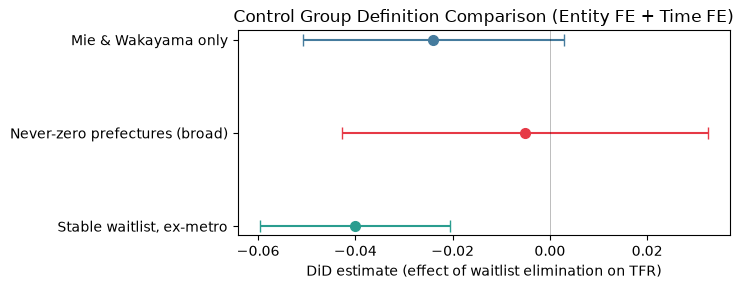

In [11]:
# ============================================================
# 対照群の定義ごとにFEモデルを実行し、結果を比較する
# ============================================================

treated_prefs = ["06 山形県", "42 長崎県"]

# 検証する対照群の定義を辞書にまとめる（全て同じモデル仕様：県FE＋年FE）
# 定義0：元の対照群候補（三重・和歌山のみ）。クラスター数が少ない点に注意
# 定義1：分析期間中一度も待機児童ゼロを達成していない県（安定性は考慮しない、最も緩い基準）
# 定義2：2016年比で2024年の待機児童数が20%以上を維持している県（＋大都市圏を除外）
control_prefs_defs = {
    "定義0（三重・和歌山のみ）": [
        "24 三重県", "30 和歌山県",
    ],
    "定義1（未処置であることのみ）": [
        "24 三重県", "30 和歌山県",
        "04 宮城県", "07 福島県", "08 茨城県",
        "33 岡山県", "25 滋賀県", "29 奈良県", "46 鹿児島県",
    ],
    "定義2（20%以上維持＋大都市圏除外）": [
        "24 三重県", "30 和歌山県",
        "25 滋賀県", "29 奈良県", "35 山口県", "41 佐賀県",
    ],
}

TREATMENT_YEAR = 2020
YEAR_START, YEAR_END = 2016, 2024


def run_fe_did(control_prefs, treated_prefs=treated_prefs):
    """
    県FE＋年FEのパネル回帰でDiD推定量（did係数）を算出する。
    """
    target_prefs = treated_prefs + control_prefs
    df_fe = df_tfr[
        (df_tfr["prefecture"].isin(target_prefs)) &
        (df_tfr["year"] >= YEAR_START) & (df_tfr["year"] <= YEAR_END)
    ].copy()

    df_fe["treated"] = df_fe["prefecture"].isin(treated_prefs).astype(int)
    df_fe["post"] = (df_fe["year"] >= TREATMENT_YEAR).astype(int)
    df_fe["did"] = df_fe["treated"] * df_fe["post"]

    df_fe = df_fe.set_index(["prefecture", "year"])
    model = PanelOLS.from_formula("tfr ~ did + EntityEffects + TimeEffects", data=df_fe)
    result = model.fit(cov_type="clustered", cluster_entity=True)
    return result, len(target_prefs)


# ============================================================
# 各定義でモデルを実行し、結果を1つの比較表にまとめる
# ============================================================
summary_rows = []
results_all = {}

for name, control_prefs in control_prefs_defs.items():
    result, n_prefs = run_fe_did(control_prefs)
    results_all[name] = result
    summary_rows.append({
        "対照群の定義": name,
        "対象県数": n_prefs,
        "did係数": result.params["did"],
        "標準誤差": result.std_errors["did"],
        "p値": result.pvalues["did"],
    })

df_summary = pd.DataFrame(summary_rows)
print(df_summary.round(4))

# ============================================================
# プロット専用の英語ラベル（文字化け防止のため、グラフ内には日本語を使わない）
# ============================================================
# 辞書のキー（日本語）→ グラフに表示する英語ラベルの対応表
plot_labels_en = {
    "定義0（三重・和歌山のみ）": "Mie & Wakayama only",
    "定義1（未処置であることのみ）": "Never-zero prefectures (broad)",
    "定義2（20%以上維持＋大都市圏除外）": "Stable waitlist, ex-metro",
}

# ============================================================
# 係数比較プロット（フォレストプロット風）
# ============================================================
model_labels = list(results_all.keys())               # 日本語キー（データ取得用）
model_labels_en = [plot_labels_en[name] for name in model_labels]  # 英語ラベル（表示用）

coefs_did  = [results_all[name].params["did"] for name in model_labels]
ci_los_did = [results_all[name].conf_int().loc["did", "lower"] for name in model_labels]
ci_his_did = [results_all[name].conf_int().loc["did", "upper"] for name in model_labels]

colors_dot = ["#457B9D", "#E63946", "#2A9D8F"]

fig, ax = plt.subplots(figsize=(7.5, 3.0))
for i, (label, coef, lo, hi, col) in enumerate(
        zip(model_labels_en, coefs_did, ci_los_did, ci_his_did, colors_dot)):
    ax.errorbar(coef, i,
                xerr=[[coef - lo], [hi - coef]],
                fmt="o", color=col, ecolor=col,
                capsize=4, markersize=7, linewidth=1.5,
                label=label)

ax.axvline(0, color="black", linestyle="-", linewidth=0.6, alpha=0.3)
ax.set_yticks(range(len(model_labels_en)))
ax.set_yticklabels(model_labels_en)   # 英語ラベルを使用（文字化け防止）
ax.set_xlabel("DiD estimate (effect of waitlist elimination on TFR)")
ax.set_title("Control Group Definition Comparison (Entity FE + Time FE)")
ax.invert_yaxis()   # 定義0を一番上に表示
plt.tight_layout()
fig.savefig("../images/model_comparison_did.png", dpi=150, bbox_inches="tight")
plt.show()

## 処置群の妥当性検証

In [12]:
# ============================================================
# 定員・需要データの読み込み（山形・長崎・大分、2016〜2021年）
# ============================================================
# 「保育所等関連状況取りまとめ」資料3シートは年によって列構成が異なるため、
# 年ごとに列位置をマップとして明示する。主な違いは以下の通り：
#   - 2016年：列名は「定員」。「(参考)地方単独保育施策」列あり
#   - 2017年：「申込児童数」列が追加。「地方単独保育施策」列あり
#   - 2018年：列名が「利用定員数」に変更。「申込児童数」あり。「地方単独」列は消滅
#   - 2019〜2021年：「利用定員数」「利用児童数」「待機児童数」のみのシンプルな構成
files = {
    2016: ("../data/保育所等関連状況取りまとめ_2016年4月1日.xlsx", "資料３", 7),
    2017: ("../data/保育所等関連状況取りまとめ_2017年4月1日.xlsx", "資料3", 6),
    2018: ("../data/保育所等関連状況取りまとめ_2018年4月1日.xlsx", "資料3", 9),
    2019: ("../data/保育所等関連状況取りまとめ_2019年4月1日.xlsx", "資料3", 9),
    2020: ("../data/保育所等関連状況取りまとめ_2020年4月1日.xlsx", "資料3", 9),
    2021: ("../data/保育所等関連状況取りまとめ_2021年4月1日.xlsx", "資料3", 6),
}
# (県：定員col, 利用児童数col, 待機児童数col, 都市：都市名col, 定員col, 利用児童数col, 待機児童数col)
col_map = {
    2016: (4, 5, 6, 9, 11, 12, 13),
    2017: (4, 6, 7, 10, 12, 14, 15),
    2018: (4, 6, 7, 9, 11, 13, 14),
    2019: (4, 5, 6, 8, 10, 11, 12),
    2020: (4, 5, 6, 8, 10, 11, 12),
    2021: (4, 5, 6, 8, 10, 11, 12),
}

# 対象県と、待機児童数集計上あわせて足す必要がある中核市（1県に複数ある場合はリストで保持）
# 長崎県は長崎市・佐世保市の2つの中核市を持つ点に注意
# 山形市は2019年から中核市に指定されたため、2016〜2018年は都市部分に登場しない
targets = {"山形県": ["山形市"], "長崎県": ["長崎市", "佐世保市"], "大分県": ["大分市"]}

rows = []
for year, (fname, sheet, data_start_row) in files.items():
    df_raw = pd.read_excel(fname, sheet_name=sheet, header=None)
    cap_c, enr_c, wl_c, cityname_c, citycap_c, cityenr_c, citywl_c = col_map[year]

    pref_rows = df_raw.iloc[data_start_row:data_start_row + 47]

    for pref, cities in targets.items():
        prow = pref_rows[pref_rows.iloc[:, 2] == pref]
        cap, enr, wl = prow.iloc[0, cap_c], prow.iloc[0, enr_c], prow.iloc[0, wl_c]

        # 該当県が持つ中核市を1つずつ検索し、見つかった分だけ加算していく
        for city in cities:
            city_mask = df_raw.iloc[:, cityname_c].astype(str).str.contains(city, na=False)
            # 該当する中核市の行が見つかった場合のみ加算する
            # （山形市は2019年より前は中核市として別掲されておらず、city_maskが全てFalseになるため、
            # このif文がFalseとなり加算がスキップされ、県の値だけがそのまま使われる）
            if city_mask.any():
                crow = df_raw[city_mask].iloc[0]
                cap += crow.iloc[citycap_c]
                enr += crow.iloc[cityenr_c]
                wl += crow.iloc[citywl_c]

        rows.append({"year": year, "prefecture": pref, "capacity": cap, "enrolled": enr, "waitlist": wl})

df_panel_capacity = pd.DataFrame(rows).sort_values(["prefecture", "year"]).reset_index(drop=True)
df_panel_capacity["demand"] = df_panel_capacity["enrolled"] + df_panel_capacity["waitlist"]

# ============================================================
# 確認出力
# ============================================================
print(df_panel_capacity)

    year prefecture  capacity  enrolled  waitlist  demand
0   2016        大分県     25549     24281       370   24651
1   2017        大分県     26207     24897       505   25402
2   2018        大分県     27563     25866        13   25879
3   2019        大分県     28431     26077        25   26102
4   2020        大分県     28939     26662        10   26672
5   2021        大分県     29168     26708         0   26708
6   2016        山形県     25208     23710         0   23710
7   2017        山形県     26662     24954        67   25021
8   2018        山形県     27289     25528        46   25574
9   2019        山形県     28120     26137        45   26182
10  2020        山形県     29001     26630         0   26630
11  2021        山形県     29307     26256         0   26256
12  2016        長崎県     37659     36105        70   36175
13  2017        長崎県     38035     36720       190   36910
14  2018        長崎県     37957     36698       157   36855
15  2019        長崎県     38610     37268        70   37338
16  2020      

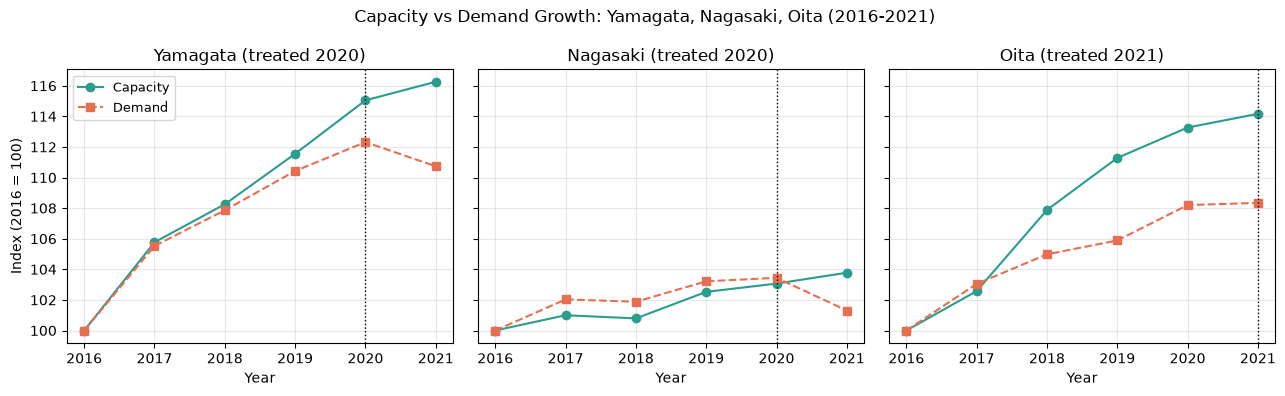

In [13]:
# ============================================================
# 可視化：定員（供給）と需要（利用児童数＋待機児童数）の推移
# ============================================================
# グラフ内の文字はすべて英語表記（日本語フォント未設定環境での文字化けを防ぐため）

treatment_year = {"山形県": 2020, "長崎県": 2020, "大分県": 2021}
pref_labels_en = {"山形県": "Yamagata", "長崎県": "Nagasaki", "大分県": "Oita"}

fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)

for ax, (pref, tyear) in zip(axes, treatment_year.items()):
    sub = df_panel_capacity[df_panel_capacity["prefecture"] == pref].sort_values("year")

    # 2016年を100とする指数化（供給と需要の伸び方を同じスケールで比較するため）
    base_cap = sub[sub["year"] == 2016]["capacity"].values[0]
    base_dem = sub[sub["year"] == 2016]["demand"].values[0]
    cap_idx = sub["capacity"] / base_cap * 100
    dem_idx = sub["demand"] / base_dem * 100

    ax.plot(sub["year"], cap_idx, marker="o", color="#2A9D8F", label="Capacity")
    ax.plot(sub["year"], dem_idx, marker="s", linestyle="--", color="#E76F51", label="Demand")

    # 各県の処置年（待機児童ゼロ達成年）に縦の目安線を入れる
    ax.axvline(x=tyear, color="black", linestyle=":", linewidth=1)
    ax.set_title(f"{pref_labels_en[pref]} (treated {tyear})")
    ax.set_xlabel("Year")
    ax.grid(alpha=0.3)

axes[0].set_ylabel("Index (2016 = 100)")
axes[0].legend(fontsize=9, loc="upper left")
fig.suptitle("Capacity vs Demand Growth: Yamagata, Nagasaki, Oita (2016-2021)")
fig.tight_layout()
fig.savefig("../images/capacity_vs_demand.png", dpi=150, bbox_inches="tight")
plt.show()

| 県 | 定員成長率 | 需要成長率 | 差 | 
| --- | --- | --- | --- |
| 山形県 | +15.0% | +12.3% | +2.7pt |
| 長崎県 | +3.1% | +3.4% | -0.4pt |
| 大分県 | +14.2% | +8.3% | +5.8pt |

- 山形県・大分県：定員成長率が需要成長率を明確に上回っており（特に大分県は+5.8ptの差）、需要の増加ペースを上回るペースで保育所整備を進めた結果として待機児童ゼロを達成したと言える。
- 長崎県：定員成長率（+3.1%）が需要成長率（+3.4%）をわずかに下回っている（-0.4pt）。つまり長崎県は保育の受け皿をほとんど増やしていないにもかかわらず、たまたま保育需要の伸びが緩やかだったことで待機児童ゼロに達した、という見方ができる。積極的な政策努力の結果というより、他の2県と比べて「消極的な形での待機児童ゼロ達成」だったと言える。

→ 処置群に長崎県を含めることは不適当。

## 処置群から長崎県を除いた感度分析

In [14]:
# ============================================================
# 感度分析：長崎県を処置群から除外した2×2 DiD
# ============================================================
# 定員・需要データの検証で、長崎県は供給拡大（定員成長）が需要成長に追いついておらず、
# 待機児童ゼロ化が保育所整備というより需要縮小によるものだった可能性が高いことが判明した。
# そこで長崎県を処置群から除外し、山形県のみを処置群とした場合に結果がどう変わるかを確認する。
treated_prefs_ex_nagasaki = ["06 山形県"]
control_prefs_ex_nagasaki = ["24 三重県", "30 和歌山県"]
target_prefs_ex_nagasaki = treated_prefs_ex_nagasaki + control_prefs_ex_nagasaki

TREATMENT_YEAR = 2020  # 山形の処置年

df_did_ex_nagasaki = df_tfr[
    (df_tfr["prefecture"].isin(target_prefs_ex_nagasaki)) &
    (df_tfr["year"] >= 2016) & (df_tfr["year"] <= 2024)
].copy()

# treatedダミー：処置群=1, 対照群=0（時間を通じて変化しない）
df_did_ex_nagasaki["treated"] = df_did_ex_nagasaki["prefecture"].isin(treated_prefs_ex_nagasaki).astype(int)
# postダミー：処置年（2020年）以降を1とする
df_did_ex_nagasaki["post"] = (df_did_ex_nagasaki["year"] >= TREATMENT_YEAR).astype(int)

# ============================================================
# 2×2 DiD回帰：treated:post の係数がDiD推定量
# 注意：処置群が山形県1県のみとなり、クラスター数が3（山形・三重・和歌山）とさらに少なくなっている
# ============================================================
model_did_ex_nagasaki = smf.ols(
    "tfr ~ treated * post",
    data=df_did_ex_nagasaki
).fit(
    cov_type="cluster",
    cov_kwds={"groups": df_did_ex_nagasaki["prefecture"]}
)
print(model_did_ex_nagasaki.summary())

                            OLS Regression Results                            
Dep. Variable:                    tfr   R-squared:                       0.657
Model:                            OLS   Adj. R-squared:                  0.612
Method:                 Least Squares   F-statistic:                     23.61
Date:                Wed, 29 Jul 2026   Prob (F-statistic):             0.0398
Time:                        15:11:09   Log-Likelihood:                 38.380
No. Observations:                  27   AIC:                            -68.76
Df Residuals:                      23   BIC:                            -63.58
Df Model:                           3                                         
Covariance Type:              cluster                                         
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept        1.4988      0.008    186.023   

/Users/takahashishinji/Japan_fertility/japan_fertility_venv/lib/python3.12/site-packages/statsmodels/base/model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 3, but rank is 1
  warnings.warn('covariance of constraints does not have full '


In [15]:
# ============================================================
# 感度分析：長崎県を処置群から除外したFEモデル（3つの対照群定義で再検証）
# ============================================================
# 定員・需要データの検証で、長崎県は供給拡大（定員成長）が需要成長に追いついておらず、
# 待機児童ゼロ化が保育所整備というより需要縮小によるものだった可能性が高いことが判明した。
# そこで長崎県を処置群から除外し、山形県のみを処置群とした場合に結果がどう変わるかを確認する。
treated_prefs_ex_nagasaki = ["06 山形県"]

# run_fe_did関数、control_prefs_defs辞書は前セルで定義済みのものをそのまま使用する

summary_rows_ex_nagasaki = []
results_all_ex_nagasaki = {}

for name, control_prefs in control_prefs_defs.items():
    result, n_prefs = run_fe_did(control_prefs, treated_prefs_ex_nagasaki)
    results_all_ex_nagasaki[name] = result
    summary_rows_ex_nagasaki.append({
        "対照群の定義": name,
        "対象県数": n_prefs,
        "did係数": result.params["did"],
        "標準誤差": result.std_errors["did"],
        "p値": result.pvalues["did"],
    })

df_summary_ex_nagasaki = pd.DataFrame(summary_rows_ex_nagasaki)
print(df_summary_ex_nagasaki.round(4))

                対照群の定義  対象県数   did係数    標準誤差      p値
0        定義0（三重・和歌山のみ）     3 -0.0312  0.0121  0.0208
1      定義1（未処置であることのみ）    10 -0.0124  0.0181  0.4955
2  定義2（20%以上維持＋大都市圏除外）     7 -0.0473  0.0079  0.0000


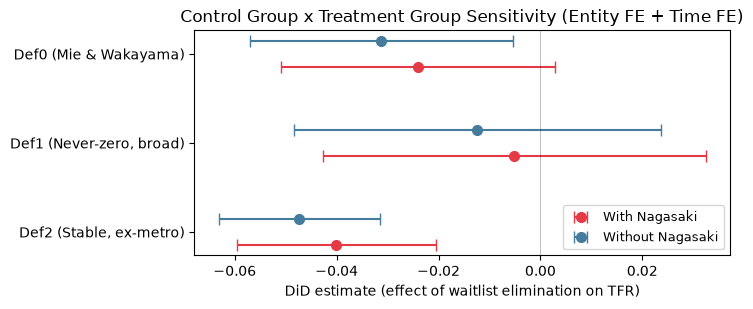

In [16]:
# ============================================================
# ペア型フォレストプロット：対照群定義 × 処置群構成（長崎県の有無）
# ============================================================
# 縦軸のカテゴリ（対照群の定義）は固定し、各カテゴリ内で
# 「長崎県を含む」「長崎県を除外」の2点を色分けして並べる。
# 縦方向＝対照群定義の違い、横方向（同じ行の2点）＝処置群構成の違い、
# という2つの軸を1枚のグラフで独立して読み取れるようにする。
model_labels = list(results_all.keys())  # 定義0・1・2（日本語キー、順序も揃っている前提）

# プロット専用の英語ラベル（文字化け防止）
plot_labels_en = {
    "定義0（三重・和歌山のみ）": "Def0 (Mie & Wakayama)",
    "定義1（未処置であることのみ）": "Def1 (Never-zero, broad)",
    "定義2（20%以上維持＋大都市圏除外）": "Def2 (Stable, ex-metro)",
}
def_labels_en = [plot_labels_en[name] for name in model_labels]

# 長崎県を含む3県版・除外した山形のみ版、それぞれの係数とCIを取り出す
coefs_with  = [results_all[name].params["did"] for name in model_labels]
ci_lo_with  = [results_all[name].conf_int().loc["did", "lower"] for name in model_labels]
ci_hi_with  = [results_all[name].conf_int().loc["did", "upper"] for name in model_labels]

coefs_ex  = [results_all_ex_nagasaki[name].params["did"] for name in model_labels]
ci_lo_ex  = [results_all_ex_nagasaki[name].conf_int().loc["did", "lower"] for name in model_labels]
ci_hi_ex  = [results_all_ex_nagasaki[name].conf_int().loc["did", "upper"] for name in model_labels]

# ============================================================
# 描画
# ============================================================
fig, ax = plt.subplots(figsize=(7.5, 3.2))
y_base = list(range(len(def_labels_en)))
offset = 0.15  # 同じ定義内で2点を上下にずらして重ならないようにする

for i, y in enumerate(y_base):
    # 長崎県を含む3県版（上側）
    ax.errorbar(coefs_with[i], y + offset,
                xerr=[[coefs_with[i] - ci_lo_with[i]], [ci_hi_with[i] - coefs_with[i]]],
                fmt="o", color="#E63946", ecolor="#E63946", capsize=4, markersize=7,
                label="With Nagasaki" if i == 0 else None)
    # 長崎県を除外した山形県のみ版（下側）
    ax.errorbar(coefs_ex[i], y - offset,
                xerr=[[coefs_ex[i] - ci_lo_ex[i]], [ci_hi_ex[i] - coefs_ex[i]]],
                fmt="o", color="#457B9D", ecolor="#457B9D", capsize=4, markersize=7,
                label="Without Nagasaki" if i == 0 else None)

ax.axvline(0, color="black", linestyle="-", linewidth=0.6, alpha=0.3)
ax.set_yticks(y_base)
ax.set_yticklabels(def_labels_en)
ax.set_xlabel("DiD estimate (effect of waitlist elimination on TFR)")
ax.set_title("Control Group x Treatment Group Sensitivity (Entity FE + Time FE)")
ax.legend(fontsize=9, loc="lower right")
ax.invert_yaxis()  # 定義0を一番上に表示（これまでの比較表と並び順を揃えるため）
plt.tight_layout()
fig.savefig("../images/model_comparison_sensitivity.png", dpi=150, bbox_inches="tight")
plt.show()

- 長崎県を除いても負の効果という方向性は変わらず、むしろ係数の負の方向が強くなった。
- 長崎県を除くと、p値はすべての対照群定義で低下した。ただし実質的な意味で有意性の判定が変わったのは定義0のみ（非有意→有意）であり、定義2はもともと強く有意、定義1は依然として全く有意ではない。
- これは「長崎県が結果を歪めていたから負の効果が出ていた」という単純な話ではなく、山形県自体の処置後のTFR低下が、対照群と比べて相対的に大きいということを示している。

以前の定員・需要データの検証で、山形県は「需要増加を上回るペースで供給拡大を行った、真正な政策効果を持つ処置群」であることが分かっている（長崎県のような"見せかけの処置"ではない）。にもかかわらず、その山形県単独で見ても対照群よりTFRの低下が大きいという今回の結果は、以前検討した2つの解釈仮説（①逆の因果関係＝需要縮小による見せかけのゼロ化、②両立支援のジレンマ仮説）のうち、①（見せかけのゼロ化）では山形県の結果を説明できないことを意味する。山形県は本物の供給拡大をしているので、①の仮説は少なくとも山形県には当てはまらない。
つまり、長崎県を除外してもなお残るこの負の効果は、②（保育所整備が両立を可能にする一方、機会費用の意識から2人目以降をためらわせる）という仮説か、あるいは単にサンプルサイズが小さすぎるがゆえの統計的なノイズのどちらかである可能性が高まったと言える。